In [1]:
!pip install tensorflow

In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

2025-10-22 16:09:23.289458: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
# Path to your single dataset folder (should have subfolders for each class)
data_dir = '/teamspace/studios/this_studio/HibisCus_Compresed_Dataset(8000img)'
# Parameters
BATCH_SIZE = 32
IMG_SIZE = (224, 224)  # DenseNet121 default input size
NUM_CLASSES = 8
EPOCHS = 50
VAL_SPLIT = 0.2  # 20% for validation
TEST_SPLIT = 0.1  # 10% for testing

In [6]:
import os
import pandas as pd
from PIL import Image
from collections import Counter

# ============================================================
# CONFIGURATION
# ============================================================
dataset_path = "/teamspace/studios/this_studio/Hibiscus and Tea  combined Dataset"

# ============================================================
# STEP 1: ANNOTATION + VALIDATION
# ============================================================
data = []
corrupted = []

for label in os.listdir(dataset_path):
    class_folder = os.path.join(dataset_path, label)
    if os.path.isdir(class_folder):
        for file in os.listdir(class_folder):
            if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                rel_path = os.path.join(label, file)
                full_path = os.path.join(dataset_path, rel_path)

                # ✅ Validation: check corrupted image
                try:
                    img = Image.open(full_path)
                    img.verify()
                    data.append([rel_path, label])
                except Exception:
                    corrupted.append(rel_path)

# ============================================================
# STEP 2: CREATE CSV
# ============================================================
if not data:
    raise ValueError("❌ No valid images found in dataset folder! Please check the path or image formats.")

df = pd.DataFrame(data, columns=['filename', 'label'])
csv_path = os.path.join(dataset_path, "labels.csv")
df.to_csv(csv_path, index=False, encoding='utf-8')

# ============================================================
# STEP 3: SUMMARY REPORT
# ============================================================
class_counts = Counter(df['label'])
total_images = len(df)

print("\n✅ Annotation & Validation Completed Successfully!")
print(f"📁 CSV file saved at: {csv_path}")
print(f"🖼️ Total valid images: {total_images}")
print(f"⚠️ Corrupted/Skipped images: {len(corrupted)}")

print("\n📊 Class-wise Image Distribution:")
for cls, count in class_counts.items():
    print(f"   • {cls}: {count} images")

# ============================================================
# STEP 4: SHOW SAMPLE FROM EACH CLASS
# ============================================================
print("\n🧾 Sample of annotation data (1 per class):")
sample_rows = []

for cls in class_counts.keys():
    sample = df[df['label'] == cls].head(1)
    sample_rows.append(sample)

samples_df = pd.concat(sample_rows, ignore_index=True)
print(samples_df)

print("\n✅ Annotation & Validation Protocol executed successfully!\n")



✅ Annotation & Validation Completed Successfully!
📁 CSV file saved at: /teamspace/studios/this_studio/Hibiscus and Tea  combined Dataset/labels.csv
🖼️ Total valid images: 7994
⚠️ Corrupted/Skipped images: 0

📊 Class-wise Image Distribution:
   • Citruspot: 1000 images
   • Early_Mild_Spotting: 1000 images
   • Fungal_Infected: 1000 images
   • Healthy: 1000 images
   • Mild_Edge_Damage: 1000 images
   • Senescent: 1000 images
   • Slightly_Diseased: 1000 images
   • Wrinkled_Leaf: 994 images

🧾 Sample of annotation data (1 per class):
                                            filename                label
0  Citruspot/aug_pil_0_b1.17_c0.76_col0.95 (Custo...            Citruspot
1  Early_Mild_Spotting/aug_pil_0_b0.86_c1.06_col1...  Early_Mild_Spotting
2  Fungal_Infected/aug_pil_0_b1.17_c0.97_col0.75.jpg      Fungal_Infected
3                     Healthy/Healthy_1 (Custom).jpg              Healthy
4  Mild_Edge_Damage/aug_pil_0_b0.78_c0.93_col0.74...     Mild_Edge_Damage
5        Senes

In [7]:
# Step 2: Load and preprocess dataset with progress bar
def load_dataset(data_dir):
    images = []
    labels = []

    for class_idx, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(data_dir, class_name)
        if not os.path.exists(class_dir):
            print(f"Warning: Directory {class_dir} not found!")
            continue

        print(f"Loading {class_name} images...")
        for img_file in tqdm(os.listdir(class_dir)):
            img_path = os.path.join(class_dir, img_file)
            try:
                with Image.open(img_path) as img:
                    img = img.convert('RGB')  # Ensure RGB format
                    img = img.resize(IMAGE_SIZE)
                    img_array = np.array(img) / 255.0
                    if img_array.shape == (*IMAGE_SIZE, 3):
                        images.append(img_array)
                        labels.append(class_idx)
            except Exception as e:
                print(f"Error loading {img_path}: {e}")

    return np.array(images), np.array(labels)

In [8]:
pip install imbalanced-learn


Note: you may need to restart the kernel to use updated packages.


In [9]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter
import tensorflow as tf
import numpy as np
import os

# 🏷️ Get class names
class_names = sorted(os.listdir(data_dir))
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

# 🖼️ Load file paths and labels
file_paths = []
labels = []

for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(data_dir, class_name)
    for img_name in os.listdir(class_dir):
        img_path = os.path.join(class_dir, img_name)
        file_paths.append(img_path)
        labels.append(class_idx)

file_paths = np.array(file_paths)
labels = np.array(labels)

# 🧼 Load and preprocess images
X_images = []
for img_path in file_paths:
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.inception_v3.preprocess_input(img)
    X_images.append(img.numpy())

X_images = np.array(X_images)
y = labels

# 🔀 Split data: 15% test first
X_temp, X_test, y_temp, y_test = train_test_split(
    X_images, y, 
    test_size=0.15, 
    random_state=42, 
    stratify=y
)

# 🔀 Now split X_temp into 82.35% train and 17.65% val to make them 70% and 15% of original
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, 
    test_size=0.1765,  # 15% of original = 15/85 ≈ 0.1765
    random_state=42, 
    stratify=y_temp
)

print(f"\nOriginal counts: {Counter(y)}")
print(f"Train: {len(X_train)} (before SMOTE), Val: {len(X_val)}, Test: {len(X_test)}")

# 🔁 Apply SMOTE
print("\nApplying SMOTE to training data...")
X_train_flat = X_train.reshape(X_train.shape[0], -1)
smote = SMOTE(random_state=42)
X_train_smote_flat, y_train_smote = smote.fit_resample(X_train_flat, y_train)
X_train_smote = X_train_smote_flat.reshape(-1, *X_train.shape[1:])

print(f"Before SMOTE: {X_train.shape[0]} samples")
print(f"After SMOTE: {X_train_smote.shape[0]} samples")
print("Class distribution after SMOTE:", Counter(y_train_smote))

# 📦 Create TF datasets
def create_dataset(X, y):
    return tf.data.Dataset.from_tensor_slices((X, tf.one_hot(y, depth=NUM_CLASSES)))

train_ds = create_dataset(X_train_smote, y_train_smote).shuffle(1000).batch(BATCH_SIZE)
val_ds = create_dataset(X_val, y_val).batch(BATCH_SIZE)
test_ds = create_dataset(X_test, y_test).batch(BATCH_SIZE)

print("\n✅ Dataset sizes:")
print(f"Training samples: {len(X_train_smote)}")
print(f"Validation samples: {len(X_val)}")
print(f"Test samples: {len(X_test)}")


Classes: ['Citruspot', 'Early_Mild_Spotting', 'Fungal_Infected', 'Healthy', 'Mild_Edge_Damage', 'Senescent', 'Slightly_Diseased', 'Wrinkled_Leaf']


I0000 00:00:1753281778.927103    2182 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 20763 MB memory:  -> device: 0, name: NVIDIA L4, pci bus id: 0000:00:04.0, compute capability: 8.9



Original counts: Counter({0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000, 7: 994})
Train: 5594 (before SMOTE), Val: 1200, Test: 1200

Applying SMOTE to training data...
Before SMOTE: 5594 samples
After SMOTE: 5600 samples
Class distribution after SMOTE: Counter({5: 700, 6: 700, 7: 700, 4: 700, 1: 700, 2: 700, 3: 700, 0: 700})

✅ Dataset sizes:
Training samples: 5600
Validation samples: 1200
Test samples: 1200


In [13]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# 🧩 Model settings
input_shape = (224, 224, 3)

# ⚙️ Load VGG16 base model with ImageNet weights (excluding top)
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=input_shape)
base_model.trainable = True  # Fine-tune entire model

# 🔨 Custom head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

# 🧠 Final model
model = Model(inputs=base_model.input, outputs=predictions)

# 🧪 Compile model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

# 📋 Summary
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,917,960 (11.13 MB)

 Trainable params: 2,883,848 (11.00 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [14]:
!pip install visualkeras

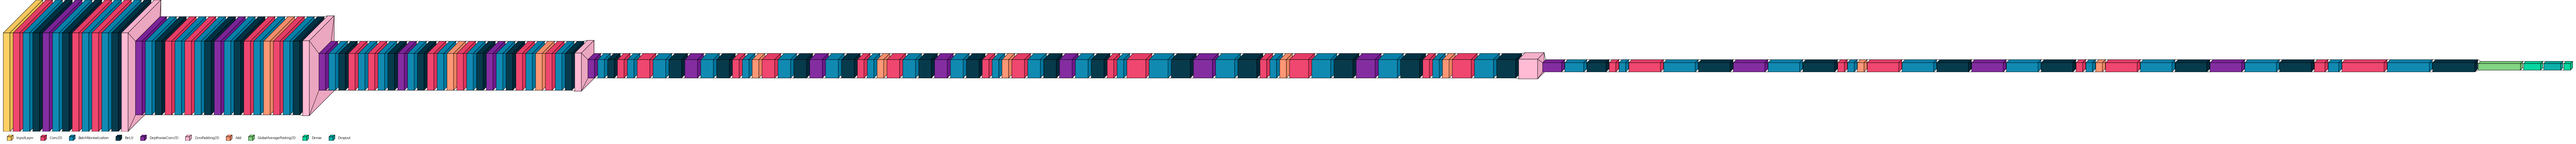

In [15]:
from visualkeras import layered_view

# Visualize the model
layered_view(model, legend=True, max_xy=300)

In [16]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# ✅ Define model name manually
model_name = "MobileNetV2"

# ✅ Callbacks (using correct model name)
checkpoint = ModelCheckpoint(
    f"{model_name}.h5",
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-4
)

# ✅ Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint, early_stop, reduce_lr]
)


Epoch 1/50


I0000 00:00:1753281936.156999    3792 service.cc:152] XLA service 0x751398003d70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753281936.157539    3792 service.cc:160]   StreamExecutor device (0): NVIDIA L4, Compute Capability 8.9
2025-07-23 14:45:36.970215: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1753281940.781396    3792 cuda_dnn.cc:529] Loaded cuDNN version 90701
2025-07-23 14:45:43.825405: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7757', 204 bytes spill stores, 204 bytes spill loads

2025-07-23 14:45:44.988356: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_7757_0', 464 byte

  2/175 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.1016 - loss: 2.4588 - precision_1: 0.1667 - recall_1: 0.0078           

I0000 00:00:1753281970.806693    3792 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.4854 - loss: 1.3930 - precision_1: 0.7205 - recall_1: 0.2917

2025-07-23 14:46:25.243725: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1225', 4 bytes spill stores, 4 bytes spill loads

2025-07-23 14:46:25.620323: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1225', 4 bytes spill stores, 4 bytes spill loads

2025-07-23 14:46:29.635100: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1218', 4 bytes spill stores, 4 bytes spill loads

2025-07-23 14:46:30.126312: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1218_0', 200 bytes spill stores, 536 bytes spill loads

2025-07-23 14:46:30.438597: I external/loc

... (12 outputs left out)

175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.9956 - loss: 0.0154 - precision_1: 0.9965 - recall_1: 0.9956 - val_accuracy: 0.9167 - val_loss: 0.3451 - val_precision_1: 0.9218 - val_recall_1: 0.9142 - learning_rate: 1.0000e-04
Epoch 20/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9965 - loss: 0.0096 - precision_1: 0.9973 - recall_1: 0.9965

175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.9965 - loss: 0.0096 - precision_1: 0.9973 - recall_1: 0.9965 - val_accuracy: 0.9542 - val_loss: 0.1984 - val_precision_1: 0.9581 - val_recall_1: 0.9533 - learning_rate: 1.0000e-04
Epoch 21/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9977 - loss: 0.0077 - precision_1: 0.9977 - recall_1: 0.9974

175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.9977 - loss: 0.0077 - precision_1: 0.9977 - recall_1: 0.9974 - val_accuracy: 0.9550 - val_loss: 0.1795 - val_precision_1: 0.9589 - val_recall_1: 0.9533 - learning_rate: 1.0000e-04
Epoch 22/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9988 - loss: 0.0048 - precision_1: 0.9992 - recall_1: 0.9984

175/175 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.9988 - loss: 0.0048 - precision_1: 0.9992 - recall_1: 0.9984 - val_accuracy: 0.9625 - val_loss: 0.1680 - val_precision_1: 0.9632 - val_recall_1: 0.9608 - learning_rate: 1.0000e-04
Epoch 23/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.9988 - loss: 0.0056 - precision_1: 0.9989 - recall_1: 0.9988 - val_accuracy: 0.9617 - val_loss: 0.1652 - val_precision_1: 0.9633 - val_recall_1: 0.9617 - learning_rate: 1.0000e-04
Epoch 24/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.9987 - loss: 0.0067 - precision_1: 0.9987 - recall_1: 0.9987 - val_accuracy: 0.9617 - val_loss: 0.1804 - val_precision_1: 0.9640 - val_recall_1: 0.9600 - learning_rate: 1.0000e-04
Epoch 25/50
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.9953 - loss: 0.0180 - precision_1: 0.9954 - recall_1: 0.9953 - val_accuracy: 0.9342 - val_loss: 0.2981 - val_precision_1: 0.9386 - val_recall_1: 0.9300 - learning_rate: 1.0000e-04
Epoch 26/50
175/

In [17]:
pip install seaborn


Note: you may need to restart the kernel to use updated packages.


38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 121ms/step
Classification Report:
                     precision    recall  f1-score   support

          Citruspot       0.93      0.97      0.95       150
Early_Mild_Spotting       0.91      0.85      0.88       150
    Fungal_Infected       0.99      0.97      0.98       150
            Healthy       0.90      0.99      0.94       150
   Mild_Edge_Damage       1.00      0.93      0.96       150
          Senescent       1.00      1.00      1.00       150
  Slightly_Diseased       0.93      0.93      0.93       150
      Wrinkled_Leaf       0.98      1.00      0.99       150

           accuracy                           0.95      1200
          macro avg       0.96      0.95      0.95      1200
       weighted avg       0.96      0.95      0.95      1200

Confusion matrix, without normalization


2025-07-23 14:52:29.126954: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


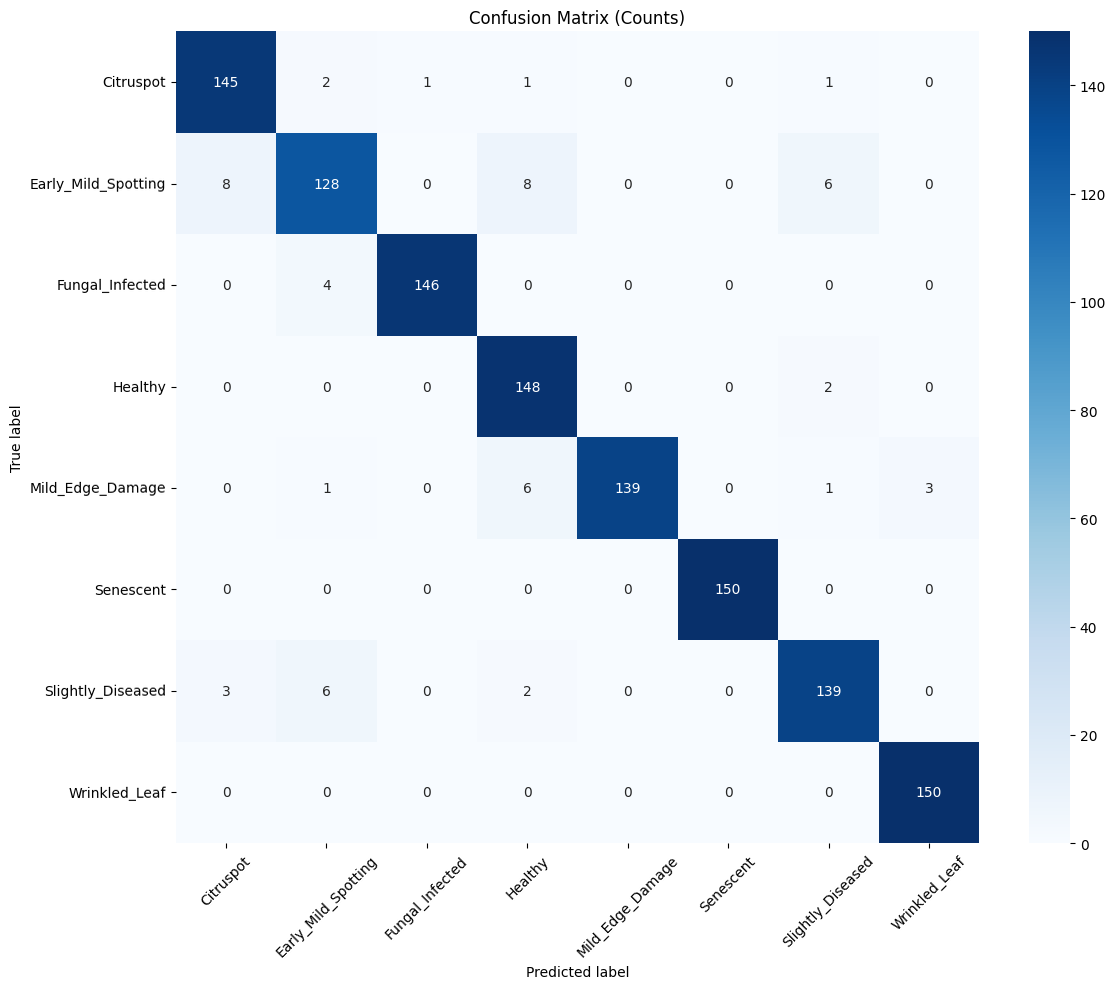

Normalized confusion matrix


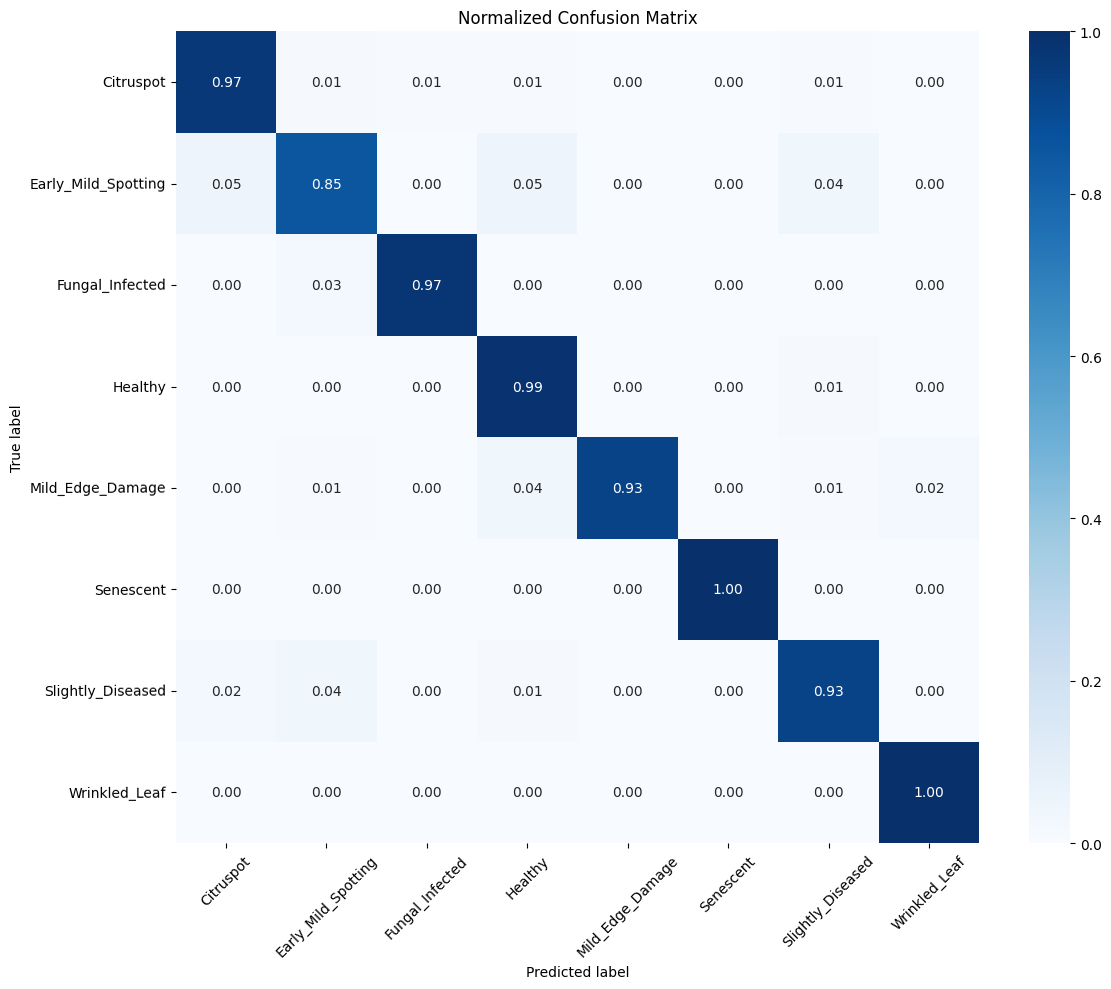

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Get predictions and true labels from test set
y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert probabilities to class indices
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds], axis=0)

# 2. Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# 3. Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, classes, normalize=False, title='Confusion matrix', cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    cm = confusion_matrix(y_true, y_pred)
    
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='.2f' if normalize else 'd',
                cmap=cmap, xticklabels=classes, yticklabels=classes)
    plt.title(title)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0.2)
    plt.tight_layout()
    plt.show()

# Plot non-normalized confusion matrix
plot_confusion_matrix(y_true, y_pred_classes, classes=class_names,
                      title='Confusion Matrix (Counts)')

# Plot normalized confusion matrix
plot_confusion_matrix(y_true, y_pred_classes, classes=class_names, normalize=True,
                      title='Normalized Confusion Matrix')

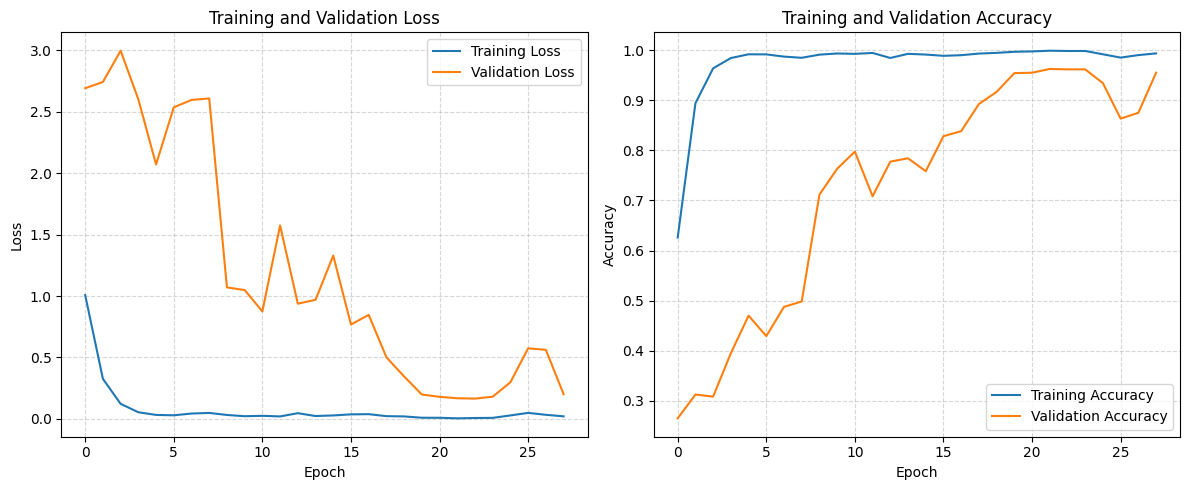


Best Validation Loss: 0.1652 at epoch 23
Corresponding Training Loss: 0.0073
Validation Accuracy at Best Epoch: 0.9617


In [21]:
import matplotlib.pyplot as plt

# Get training history from model.fit()
history = model.history.history

# Create figure with two subplots
plt.figure(figsize=(12, 5))

# 1. Plot Loss Curves
plt.subplot(1, 2, 1)
plt.plot(history['loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# 2. Plot Accuracy Curves
plt.subplot(1, 2, 2)
plt.plot(history['accuracy'], label='Training Accuracy')
plt.plot(history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Optional: Print best validation accuracy
best_val_epoch = np.argmin(history['val_loss'])
print(f"\nBest Validation Loss: {min(history['val_loss']):.4f} at epoch {best_val_epoch + 1}")
print(f"Corresponding Training Loss: {history['loss'][best_val_epoch]:.4f}")
print(f"Validation Accuracy at Best Epoch: {history['val_accuracy'][best_val_epoch]:.4f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


2025-07-23 14:52:31.445308: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


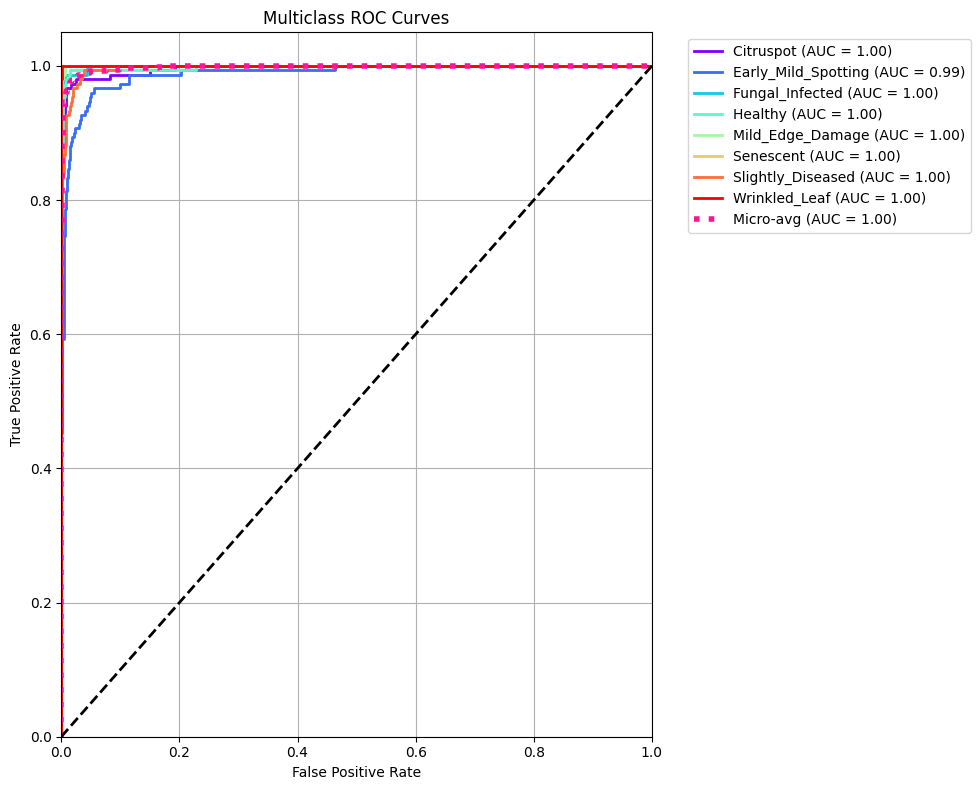


AUC Scores:
Citruspot: 0.9961
Early_Mild_Spotting: 0.9881
Fungal_Infected: 0.9993
Healthy: 0.9977
Mild_Edge_Damage: 0.9999
Senescent: 1.0000
Slightly_Diseased: 0.9970
Wrinkled_Leaf: 1.0000

Micro-average AUC: 0.9978


In [20]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

# 1. Get predictions and true labels from test set
y_pred = model.predict(test_ds)
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_true_labels = np.argmax(y_true, axis=1)  # Convert one-hot to labels

# 2. Binarize the true labels for multiclass ROC
y_true_bin = label_binarize(y_true_labels, classes=np.arange(NUM_CLASSES))

# 3. Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 4. Compute micro-average ROC curve and area
fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# 5. Generate enough colors for all classes
colors = cycle(plt.cm.rainbow(np.linspace(0, 1, NUM_CLASSES)))

# 6. Plot ROC curves
plt.figure(figsize=(10, 8))
for i, color in zip(range(NUM_CLASSES), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='{0} (AUC = {1:0.2f})'.format(class_names[i], roc_auc[i]))

# Plot micro-average curve
plt.plot(fpr["micro"], tpr["micro"],
         label='Micro-avg (AUC = {0:0.2f})'.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

# Plot random guessing line
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curves')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# 7. Print AUC scores
print("\nAUC Scores:")
for i in range(NUM_CLASSES):
    print(f"{class_names[i]}: {roc_auc[i]:.4f}")
print(f"\nMicro-average AUC: {roc_auc['micro']:.4f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


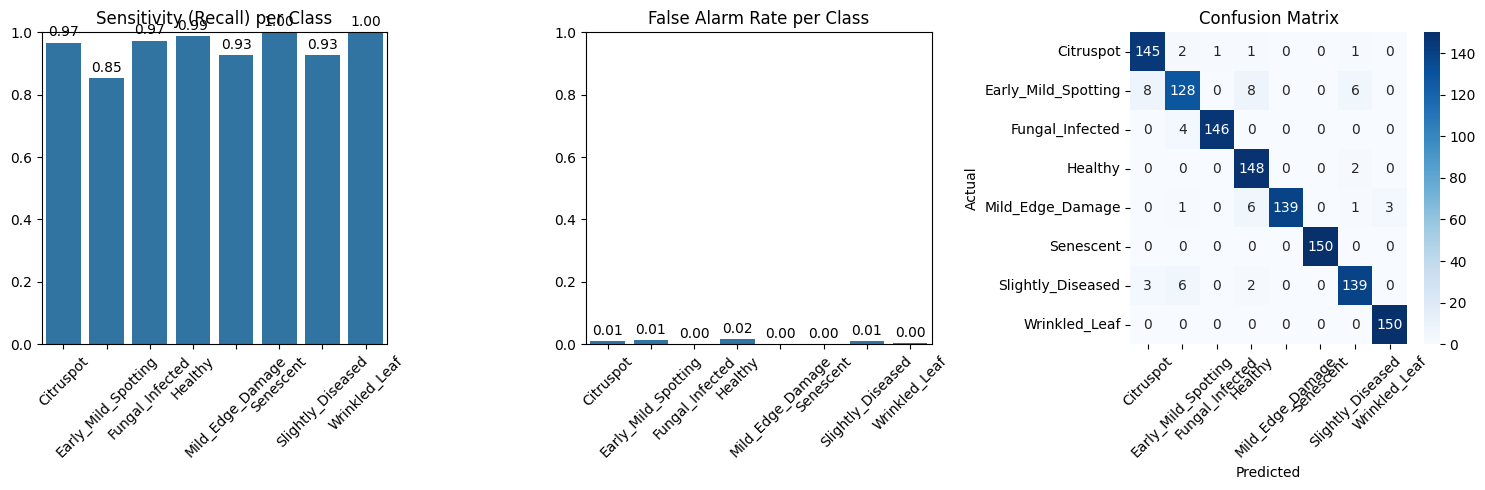


Class-wise Performance Metrics:
Class          Sensitivity    False Alarm Rate    
--------------------------------------------------
Citruspot      0.9667         0.0105              
Early_Mild_Spotting0.8533         0.0124              
Fungal_Infected0.9733         0.0010              
Healthy        0.9867         0.0162              
Mild_Edge_Damage0.9267         0.0000              
Senescent      1.0000         0.0000              
Slightly_Diseased0.9267         0.0095              
Wrinkled_Leaf  1.0000         0.0029              

Macro-average Sensitivity: 0.9542
Macro-average False Alarm Rate: 0.0065


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, recall_score

# 1. Get predictions and true labels
y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds], axis=0)

# 2. Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# 3. Calculate metrics for each class
sensitivity = []
false_alarm_rate = []
precision = []

for i in range(len(class_names)):
    # Sensitivity (Recall)
    sensitivity.append(recall_score(y_true, y_pred_classes, labels=[i], average=None)[0])
    
    # False Alarm Rate = FP / (FP + TN)
    fp = np.sum(cm[:, i]) - cm[i, i]
    tn = np.sum(cm) - np.sum(cm[i, :]) - np.sum(cm[:, i]) + cm[i, i]
    false_alarm_rate.append(fp / (fp + tn))


# 4. Create visualization
plt.figure(figsize=(15, 5))

# Sensitivity plot
plt.subplot(1, 3, 1)
sns.barplot(x=class_names, y=sensitivity)
plt.title('Sensitivity (Recall) per Class')
plt.ylim(0, 1)
plt.xticks(rotation=45)
for i, v in enumerate(sensitivity):
    plt.text(i, v+0.02, f"{v:.2f}", ha='center')

# False Alarm Rate plot
plt.subplot(1, 3, 2)
sns.barplot(x=class_names, y=false_alarm_rate)
plt.title('False Alarm Rate per Class')
plt.ylim(0, 1)
plt.xticks(rotation=45)
for i, v in enumerate(false_alarm_rate):
    plt.text(i, v+0.02, f"{v:.2f}", ha='center')

# Confusion Matrix
plt.subplot(1, 3, 3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# 5. Print metrics table
print("\nClass-wise Performance Metrics:")
print(f"{'Class':<15}{'Sensitivity':<15}{'False Alarm Rate':<20}")
print("-"*50)
for i in range(len(class_names)):
    print(f"{class_names[i]:<15}{sensitivity[i]:<15.4f}{false_alarm_rate[i]:<20.4f}")


# 6. Calculate macro averages
macro_sensitivity = np.mean(sensitivity)
macro_far = np.mean(false_alarm_rate)
print(f"\nMacro-average Sensitivity: {macro_sensitivity:.4f}")
print(f"Macro-average False Alarm Rate: {macro_far:.4f}")

In [ ]:
# 🔍 Production Inference Function for Hibiscus Leaf Disease
import numpy as np
from PIL import Image
import tensorflow as tf

def predict_hibiscus_disease(image_path, model, class_names):
    """
    Run inference on a single hibiscus leaf image.
    Applies MobileNetV2 / InceptionV3 [-1, 1] normalization matching training.
    """
    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))
    arr = np.array(img, dtype=np.float32)
    arr = np.expand_dims(arr, axis=0)
    arr = tf.keras.applications.mobilenet_v2.preprocess_input(arr)
    
    preds = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(preds))
    confidence = float(preds[idx] * 100)
    
    print("Predicted Class:", class_names[idx], f"({confidence:.2f}%)")
    print("Class Probabilities:")
    for i, (name, prob) in enumerate(zip(class_names, preds)):
        print(f"  {i}: {name:<20} -> {prob*100:.2f}%")
        
    return {
        "class": class_names[idx],
        "confidence": confidence,
        "probabilities": {name: float(prob) for name, prob in zip(class_names, preds)}
    }

# Example usage:
# result = predict_hibiscus_disease("sample_leaf.jpg", model, class_names)
